# Notebook 18 — Corpus inputs for the design of the tracking studies

Added November 17, 2026, for the design memo of the four studies of the tracking paper (`Docs/Memorandum/`). The memo first called them Experiments 3A to 3D of a Study 3; on November 18, 2026 they became Studies 2 to 5, and on November 19 they became Studies 1 to 4 of the tracking paper, so 3A is Study 1, 3B is Study 2, 3C is Study 3 and 3D is Study 4. The completed listing-and-rating study reported in the law review article is called the law review study. Counting only: no language model is called and nothing upstream changes. Outputs go to `v4_rebuild/18_tracking_studies_design/`. The law review study's item means it reads are written by `Analysis/tracking_studies_design/design_inputs_from_law_review_study.Rmd`; knit that file first.

**The model behind Studies 1 to 4.** A story feature F can be in a disputed work D of genre g for three reasons: any film might have it (background), films of the genre tend to have it (the genre), or D's makers took it from an earlier work W (copying). Write p = P(F | g) for prevalence and b = P(F | not g) for the feature's rate outside the genre. If background and genre act independently, the genre's own strength q satisfies p = b + q − bq. Three questions then have three different answers.

1. *Is the shared feature evidence of copying?* If a copier reproduces the feature and an independent author includes it with probability p, sharing it multiplies the odds of copying by 1 ÷ p. The weight of the evidence is −log p, the feature's surprisal in the genre. It depends on prevalence alone.
2. *How much does the genre add?* The absolute increase is p − b (incremental category validity; with all films as the baseline, p − P(F)). As a strength it is q = (p − b) ÷ (1 − b), Cheng's causal power and Pearl's probability of sufficiency.
3. *Given that the feature is in this work, and was not copied, is it there because of the genre?* The share of the genre's instances that the genre itself accounts for is (p − b) ÷ p = 1 − 1 ÷ lift, Pearl's probability of necessity. Within a genre it orders features as distinctiveness does.

All three are built from the same excess p − b. They differ in what they divide by.

**What this notebook counts.** (A) the three quantities for every story feature and genre, and the check that they order features as stated; (B) the law review study's rated items with these quantities and their mean ratings in that study, which shows where the accounts of lay judgment disagree; (C) how much two unrelated films of a genre share by chance, and whether weighting shared features by surprisal picks out films that share a title (a rough stand-in for remakes and adaptations); (D) pairs of features in which one nearly implies the other, for the experiment on packages; (E) how many concrete features each genre has in each cell, for building synopses.

In [1]:
import shutil, tempfile, re
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt

try:
    from google.colab import drive  # type: ignore
    drive.mount('/content/drive')
except Exception:
    pass

_CANDS = [
    Path('/content/drive/MyDrive/DGK Lab/Reasoning Lab/'
         'DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild'),
    Path('/Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/'
         'My Drive/DGK Lab/Reasoning Lab/'
         'DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild'),
    Path.cwd() / 'v4_rebuild',
    Path.cwd().parent / 'v4_rebuild',
]
V4 = next((c for c in _CANDS if c.exists()), None)
assert V4 is not None, 'Could not locate v4_rebuild; set V4 manually.'
OUT = V4 / '18_tracking_studies_design'
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
TMP = Path(tempfile.mkdtemp())
def read_parquet(p, **kw):
    local = TMP / p.name          # Drive sometimes serves partial parquet files; read a local copy
    shutil.copy(p, local)
    return pd.read_parquet(local, **kw)

plt.rcdefaults()
plt.rcParams.update({'font.size': 10, 'savefig.facecolor': 'white'})
BLUE, RED, GRAY = '#1f77b4', '#d62728', '#7f7f7f'
ERR = dict(ecolor='black', capsize=3, elinewidth=1)
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / 'figures' / f'{name}.png', dpi=200, facecolor='white')
    plt.show()
SEED = 20260219
SIX = ['Western', 'Horror', 'Science Fiction', 'Crime', 'Fantasy', 'Comedy']
report = []
def out(s=''):
    print(s); report.append(s)
print('V4 =', V4)

V4 = /Users/USER/Library/CloudStorage/GoogleDrive-ACCOUNT/My Drive/DGK Lab/Reasoning Lab/DGK Lab - Scene A Faire Computational/Analysis/v4_rebuild


## Load the counts

Prevalence comes from the scored table. The rate outside the genre needs the number of distinct films with the feature, counted from the element index as in Notebook 17.

In [2]:
cls = read_parquet(V4 / '03b_classification' / 'stockiness_long_classified.parquet')
films = read_parquet(V4 / '01c_union' / 'movies_union.parquet', columns=['union_id', 'name', 'year', 'genres_canonical'])
N = films['union_id'].nunique()
idx = read_parquet(V4 / '02_elements' / 'element_index.parquet').drop_duplicates()
n_f = idx.groupby(['element', 'element_type'])['union_id'].nunique().rename('n_f').reset_index()
d = cls.merge(n_f, on=['element', 'element_type'], how='left')
d['N_g'] = (d['film_count'] / d['rel_freq_in_genre']).round().astype(int)
d['p'] = d['film_count'] / d['N_g']                                   # prevalence, P(F | g)
d['base'] = d['n_f'] / N                                              # P(F), all films
d['b'] = (d['n_f'] - d['film_count']) / (N - d['N_g'])                # P(F | not g)
d['cue'] = d['film_count'] / d['n_f']                                 # raw cue validity, P(g | F), distinct films
d['icv'] = d['p'] - d['base']                                         # incremental category validity
d['excess'] = d['p'] - d['b']                                         # the same increment against films outside the genre
d['power'] = (d['excess'] / (1 - d['b'])).clip(lower=0)               # causal power / probability of sufficiency
d['share_genre'] = (d['excess'] / d['p']).clip(lower=0)               # probability of necessity: 1 - 1/lift
d['surprisal_bits'] = -np.log2(d['p'])                                # weight of a shared feature as evidence of copying
d['lr_copy'] = 1 / d['p']
nar = d[d['is_narrative_element']].copy()
out('NOTEBOOK 18 — CORPUS INPUTS FOR THE DESIGN OF THE TRACKING STUDIES')
out(f'{N:,} films; {len(nar):,} story-feature cells in {nar.genre.nunique()} genres')

NOTEBOOK 18 — CORPUS INPUTS FOR THE DESIGN OF THE TRACKING STUDIES
45,958 films; 237,516 story-feature cells in 17 genres


## Part A. Three questions, three quantities

The check: within each genre, the single-case share (p − b) ÷ p should order story features as distinctiveness does, the genre's strength (p − b) ÷ (1 − b) should order them as incremental category validity does, and the copying weight is prevalence turned upside down. Then the worked example of the paper's Part VI with the three quantities side by side.

In [3]:
rows = []
for g, x in nar.groupby('genre'):
    r = lambda a, b_: x[a].rank().corr(x[b_].rank())
    rows.append({'genre': g, 'share~distinctiveness': r('share_genre', 'posterior_smoothed'), 'share~cue validity': r('share_genre', 'cue'),
                 'power~increment': r('power', 'icv'), 'share~prevalence': r('share_genre', 'p'), 'power~distinctiveness': r('power', 'posterior_smoothed')})
chk = pd.DataFrame(rows).set_index('genre')
chk.to_csv(OUT / 'partA_rank_checks.csv')
out(''); out('A. WITHIN-GENRE SPEARMAN CORRELATIONS AMONG STORY FEATURES, mean over 17 genres (min, max)')
for c in chk.columns:
    out(f'  {c:<26} {chk[c].mean():.3f}  ({chk[c].min():.3f}, {chk[c].max():.3f})')
out(f"  share of story-feature cells in which the genre lowers the feature's rate (p < b): {(nar['excess'] < 0).mean():.3f}")
WORKED = [('outlaw', 'noun'), ('saloon', 'noun'), ('sheriff', 'noun'), ('stagecoach', 'noun'), ('wagon train', 'chunk'),
          ('bounty hunter', 'chunk'), ('father', 'noun'), ('lawyer', 'noun'), ('chair', 'noun')]
w = d[(d.genre == 'Western')].set_index(['element', 'element_type']).loc[WORKED].reset_index()
tab = w[['element', 'film_count', 'n_f', 'p', 'b', 'cue', 'icv', 'power', 'share_genre', 'lr_copy', 'surprisal_bits']].copy()
tab.columns = ['feature', 'Westerns with it', 'all films with it', 'prevalence p', 'rate outside b', 'cue validity', 'increment p-P(F)',
               'genre strength', 'share due to genre', 'copying ratio 1/p', 'bits']
tab.to_csv(OUT / 'partA_worked_example.csv', index=False)
out(''); out('A. THE WORKED EXAMPLE (Westerns; 1,362 films)')
out(tab.round(3).to_string(index=False))


A. WITHIN-GENRE SPEARMAN CORRELATIONS AMONG STORY FEATURES, mean over 17 genres (min, max)
  share~distinctiveness      0.959  (0.886, 0.989)
  share~cue validity         0.960  (0.887, 0.990)
  power~increment            0.960  (0.887, 0.990)
  share~prevalence           0.260  (0.041, 0.401)
  power~distinctiveness      0.862  (0.810, 0.886)
  share of story-feature cells in which the genre lowers the feature's rate (p < b): 0.416

A. THE WORKED EXAMPLE (Westerns; 1,362 films)
      feature  Westerns with it  all films with it  prevalence p  rate outside b  cue validity  increment p-P(F)  genre strength  share due to genre  copying ratio 1/p  bits
       outlaw               195                289         0.143           0.002         0.675             0.137           0.141               0.985              6.985 2.804
       saloon               150                226         0.110           0.002         0.664             0.105           0.109               0.985              9.080

## Part B. The law review study's items under each account

The law review study rated 48 items per genre, twelve in each cell of high or low prevalence crossed with high or low distinctiveness, for how expected each is in a typical film of the genre. The table gives, for each cell, the typical prevalence and what it implies for copying (the ratio 1 ÷ p and its weight in bits), the typical share due to the genre, and the mean rating in the law review study. The figure shows every rated item.

What to look for. If people judge copying as the model says, judged evidence of copying should fall with prevalence and ignore distinctiveness: the two low-prevalence cells should be alike and both above the two high-prevalence cells. If people judge copying by how expected the feature feels, the order is the law review study's ratings turned upside down: characteristic features, common or rare, are discounted most.

In [4]:
stim = pd.read_csv(V4 / '10_human_study_stimuli' / 'stimuli_long.csv')
im = pd.read_csv(OUT / 'law_review_study_item_means.csv')
stim = stim.merge(im[['item_id', 'n_raters', 'mean_rating', 'se_rating']], on='item_id', how='left', validate='one_to_one')
assert stim['mean_rating'].notna().all()
Ng = d.drop_duplicates('genre').set_index('genre')['N_g']
stim['N_g'] = stim['genre'].map(Ng)
stim['n_in_genre'] = np.where(stim['is_foil'], stim['film_count_in_target_genre'], stim['film_count'])
stim['p'] = stim['n_in_genre'] / stim['N_g']
stim = stim.merge(n_f, on=['element', 'element_type'], how='left')
stim['b'] = (stim['n_f'] - stim['n_in_genre']) / (N - stim['N_g'])
stim['cue'] = stim['n_in_genre'] / stim['n_f']
stim['icv'] = stim['p'] - stim['n_f'] / N
stim['share_genre'] = ((stim['p'] - stim['b']) / stim['p']).clip(lower=0)
stim['p_smoothed'] = (stim['n_in_genre'] + 0.5) / (stim['N_g'] + 1)        # foils can have no film in the target genre
stim['surprisal_bits'] = -np.log2(stim['p_smoothed'])
stim.to_csv(OUT / 'partB_law_review_study_items_with_quantities.csv', index=False)
order = ['HH', 'HL', 'LH', 'LL', 'FOIL']
cellt = stim.groupby('cell_code').agg(items=('item_id', 'size'), median_prevalence_pct=('p', lambda x: 100 * x.median()),
                                      median_copy_ratio=('p_smoothed', lambda x: (1 / x).median()), median_bits=('surprisal_bits', 'median'),
                                      median_cue_validity_pct=('cue', lambda x: 100 * x.median()), median_share_due_to_genre=('share_genre', 'median'),
                                      mean_law_review_study_rating=('mean_rating', 'mean')).loc[order]
cellt.to_csv(OUT / 'partB_cells.csv')
out(''); out('B. THE LAW REVIEW STUDY RATED ITEMS BY CELL (H = top third of the genre, L = bottom third; prevalence first, distinctiveness second)')
out(cellt.round(2).to_string())
s48 = stim[~stim['is_foil']].copy()
for c in ['mean_rating', 'surprisal_bits', 'distinctiveness_pct', 'prevalence_pct', 'share_genre', 'icv']:
    s48[c + '_c'] = s48[c] - s48.groupby('genre')[c].transform('mean')            # centered within genre
cor = s48[[c + '_c' for c in ['mean_rating', 'surprisal_bits', 'prevalence_pct', 'distinctiveness_pct', 'share_genre', 'icv']]].corr(method='spearman')
cor.index = cor.columns = ['law review study rating', 'copying weight (bits)', 'prevalence pct', 'distinctiveness pct', 'share due to genre', 'increment']
cor.to_csv(OUT / 'partB_item_correlations.csv')
out(''); out('B. SPEARMAN CORRELATIONS ACROSS THE 288 STRATIFIED ITEMS (each variable centered within genre)')
out(cor.round(2).to_string())
by_genre = s48.groupby(['genre', 'cell_code']).agg(prev=('p', lambda x: 100 * x.median()), bits=('surprisal_bits', 'median')).unstack()
out(''); out('B. MEDIAN PREVALENCE (%) AND COPYING WEIGHT (bits) BY GENRE AND CELL')
out(by_genre.round(2).to_string())


B. THE LAW REVIEW STUDY RATED ITEMS BY CELL (H = top third of the genre, L = bottom third; prevalence first, distinctiveness second)
           items  median_prevalence_pct  median_copy_ratio  median_bits  median_cue_validity_pct  median_share_due_to_genre  mean_law_review_study_rating
cell_code                                                                                                                                                
HH            72                   3.18              31.34         4.97                    31.73                       0.77                          5.65
HL            72                   3.26              30.51         4.93                     6.21                       0.00                          4.38
LH            72                   0.75             130.33         7.03                    35.32                       0.78                          5.17
LL            72                   0.77             129.12         7.00                     5.88

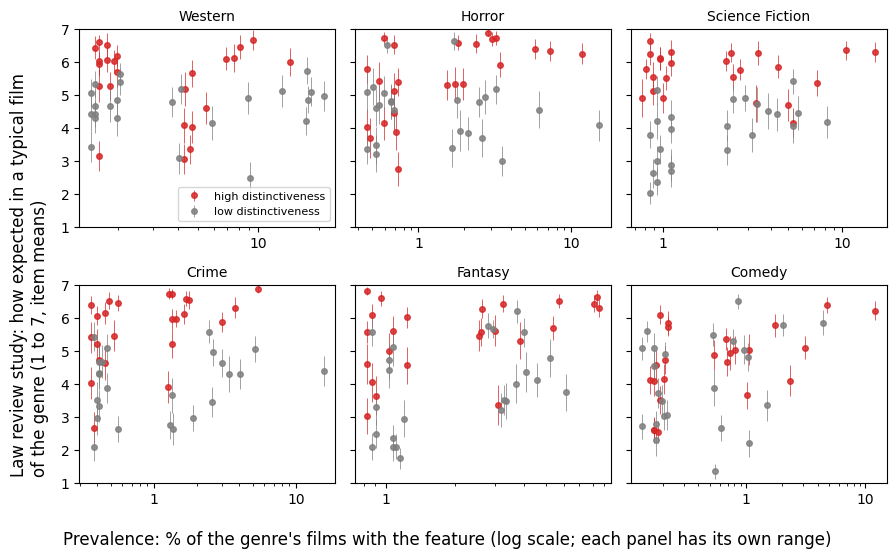

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(9.1, 5.6), sharey=True)
for ax, g in zip(axes.ravel(), SIX):
    x = s48[s48.genre == g]
    for hi, col, lab in [(True, RED, 'high distinctiveness'), (False, GRAY, 'low distinctiveness')]:
        y = x[x.cell_code.str[1].eq('H') == hi]
        ax.errorbar(100 * y['p'], y['mean_rating'], yerr=1.96 * y['se_rating'], fmt='o', ms=4, color=col, ecolor=col, elinewidth=0.6, alpha=0.85, label=lab)
    ax.set_xscale('log'); ax.set_title(g, fontsize=10); ax.set_ylim(1, 7)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
axes[0, 0].legend(fontsize=8, loc='lower right')
fig.supxlabel("Prevalence: % of the genre's films with the feature (log scale; each panel has its own range)")
fig.supylabel('Law review study: how expected in a typical film\nof the genre (1 to 7, item means)')
save(fig, 'law_review_study_items_expected_by_prevalence')

## Part C. How much do two unrelated films of a genre share?

A claim that shared features show copying needs a baseline: what two films of the genre share when neither was taken from the other. For each of the six genres of the law review study, 20,000 pairs of different films are drawn at random from the genre's films. For each pair the notebook counts the story features both summaries contain and adds up their copying weights (−log₂ of each shared feature's prevalence in the genre, with one half added to the counts). It also takes 300 films per genre and finds, for each, the other film of the genre that shares the most: a plaintiff who searches a whole genre for the closest match finds far more than a random pair shares.

The counts depend on how long the summaries are, and a plot summary is not the film. These numbers size the design; they are not evidence about any dispute.

In [6]:
pairs = cls[cls['is_narrative_element']][['element', 'element_type']].drop_duplicates().reset_index(drop=True)
pairs['col'] = pairs.index
fid = {u: i for i, u in enumerate(films['union_id'])}
ix = idx.merge(pairs, on=['element', 'element_type'])
X = sparse.csr_matrix((np.ones(len(ix), dtype=np.float32), (ix['union_id'].map(fid).to_numpy(), ix['col'].to_numpy())),
                      shape=(len(films), len(pairs)))
X.data[:] = 1
films['genres'] = films['genres_canonical'].map(lambda g: [str(v) for v in list(g)] if g is not None else [])
GEN = sorted(cls['genre'].unique())
member = {g: np.array([g in gs for gs in films['genres']]) for g in GEN}
n_feat = np.asarray(X.sum(1)).ravel()
def genre_weights(g):
    Xg = X[member[g]]
    p = (np.asarray(Xg.sum(0)).ravel() + 0.5) / (Xg.shape[0] + 1)
    return Xg, -np.log2(p)
rng = np.random.default_rng(SEED)
def random_pairs(n_rows, k):
    i = rng.integers(0, n_rows, k); j = rng.integers(0, n_rows, k)
    keep = i != j
    return i[keep], j[keep]
rows = []; store = {}
for g in SIX:
    Xg, bits = genre_weights(g)
    i, j = random_pairs(Xg.shape[0], 20000)
    S = Xg[i].multiply(Xg[j]).tocsr()
    cnt = np.asarray(S.sum(1)).ravel(); wt = S @ bits
    samp = rng.choice(Xg.shape[0], size=min(300, Xg.shape[0]), replace=False)
    C = (Xg[samp] @ Xg.T).toarray(); W = (Xg[samp].multiply(bits) @ Xg.T).toarray()
    C[np.arange(len(samp)), samp] = -1; W[np.arange(len(samp)), samp] = -1
    store[g] = dict(count=cnt, bits=wt, nn_count=C.max(1), nn_bits=W.max(1))
    rows.append({'genre': g, 'films': Xg.shape[0], 'features per summary (median)': float(np.median(np.asarray(Xg.sum(1)).ravel())),
                 'shared features: median': float(np.median(cnt)), 'mean': float(cnt.mean()), '95th pct': float(np.percentile(cnt, 95)), '99th pct': float(np.percentile(cnt, 99)),
                 'shared bits: median': float(np.median(wt)), 'bits 95th': float(np.percentile(wt, 95)), 'bits 99th': float(np.percentile(wt, 99)),
                 'closest other film: shared features (median)': float(np.median(C.max(1))), 'closest other film: bits (median)': float(np.median(W.max(1)))})
null = pd.DataFrame(rows).set_index('genre')
null.to_csv(OUT / 'partC_chance_overlap.csv')
out(''); out('C. WHAT TWO UNRELATED FILMS OF A GENRE SHARE (20,000 random pairs per genre; closest match for 300 films per genre)')
out(null.round(1).T.to_string())


C. WHAT TWO UNRELATED FILMS OF A GENRE SHARE (20,000 random pairs per genre; closest match for 300 films per genre)
genre                                         Western  Horror  Science Fiction   Crime  Fantasy   Comedy
films                                          1362.0  4363.0           2590.0  5564.0   2429.0  14724.0
features per summary (median)                    39.0    58.0             69.0    44.0     70.0     37.0
shared features: median                           2.0     3.0              3.0     2.0      3.0      1.0
mean                                              3.5     4.6              5.0     3.6      4.9      2.3
95th pct                                         11.0    16.0             16.0    13.0     16.0      8.0
99th pct                                         19.0    24.0             23.0    20.0     23.0     14.0
shared bits: median                               5.9     6.8              8.6     5.8      8.6      4.2
bits 95th                                  

### Films that share a title

The corpus has no record of which films derive from which. Films with the same title released at least three years apart are a rough stand-in: many are remakes or adaptations of one source, and some are unrelated films that happen to share a name, which works against the test. For every genre with at least 20 such pairs, each scoring rule is asked to tell same-title pairs from random pairs of the genre (AUC: 0.5 is guessing, 1 is perfect). The rules are the plain number of shared story features, the shared features weighted by copying weight (−log₂ prevalence), and the shared features weighted by distinctiveness. Because long summaries share more, each rule is also computed after dividing by the geometric mean of the two summaries' feature counts.

In [7]:
films['key'] = films['name'].astype(str).str.lower().str.replace(r'[^a-z0-9 ]', '', regex=True).str.strip()
films['row'] = np.arange(len(films))
grp = films[films['key'].str.len() > 0].groupby('key')
pos = []
for k, x in grp:
    if len(x) < 2 or len(x) > 6:
        continue
    r = x[['row', 'year']].dropna().to_numpy()
    for a in range(len(r)):
        for b_ in range(a + 1, len(r)):
            if abs(r[a, 1] - r[b_, 1]) >= 3:
                pos.append((int(r[a, 0]), int(r[b_, 0])))
pos = np.array(pos)
dist_w = {}
for g in GEN:
    x = cls[(cls.genre == g) & cls.is_narrative_element].merge(pairs, on=['element', 'element_type'])
    v = np.zeros(len(pairs)); v[x['col'].to_numpy()] = x['posterior_smoothed'].to_numpy(); dist_w[g] = v
def scores(Xa, Xb, bits, dw, na, nb_):
    S = Xa.multiply(Xb).tocsr()
    norm = np.sqrt(np.maximum(na, 1) * np.maximum(nb_, 1))
    c = np.asarray(S.sum(1)).ravel(); s = S @ bits; dd = S @ dw
    return {'shared features': c, 'weighted by copying weight': s, 'weighted by distinctiveness': dd,
            'shared features, length-adjusted': c / norm, 'copying weight, length-adjusted': s / norm, 'distinctiveness, length-adjusted': dd / norm}
aucs = []
for g in GEN:
    m = member[g]; rows_g = np.where(m)[0]
    pg = pos[m[pos[:, 0]] & m[pos[:, 1]]]
    if len(pg) < 20:
        continue
    _, bits = genre_weights(g)
    i, j = random_pairs(len(rows_g), 5000); ni, nj = rows_g[i], rows_g[j]
    sp = scores(X[pg[:, 0]], X[pg[:, 1]], bits, dist_w[g], n_feat[pg[:, 0]], n_feat[pg[:, 1]])
    sn = scores(X[ni], X[nj], bits, dist_w[g], n_feat[ni], n_feat[nj])
    y = np.r_[np.ones(len(pg)), np.zeros(len(ni))]
    aucs.append({'genre': g, 'same-title pairs': len(pg), **{k: roc_auc_score(y, np.r_[sp[k], sn[k]]) for k in sp}})
auc = pd.DataFrame(aucs).set_index('genre')
auc.to_csv(OUT / 'partC_same_title_auc.csv')
rules = [c for c in auc.columns if c != 'same-title pairs']
wmean = {k: float(np.average(auc[k], weights=auc['same-title pairs'])) for k in rules}
out(''); out(f"C. TELLING SAME-TITLE PAIRS FROM RANDOM PAIRS OF THE GENRE (AUC; {len(pos):,} same-title pairs at least three years apart; {len(auc)} genres with 20 or more)")
out(auc.round(3).to_string())
out('Mean over genres, weighted by the number of same-title pairs: ' + '; '.join(f'{k} {v:.3f}' for k, v in wmean.items()))


C. TELLING SAME-TITLE PAIRS FROM RANDOM PAIRS OF THE GENRE (AUC; 3,204 same-title pairs at least three years apart; 17 genres with 20 or more)
                 same-title pairs  shared features  weighted by copying weight  weighted by distinctiveness  shared features, length-adjusted  copying weight, length-adjusted  distinctiveness, length-adjusted
genre                                                                                                                                                                                                           
Action                        234            0.693                       0.711                        0.703                             0.729                            0.745                             0.741
Adventure                     198            0.797                       0.828                        0.816                             0.855                            0.874                             0.864
Animation           

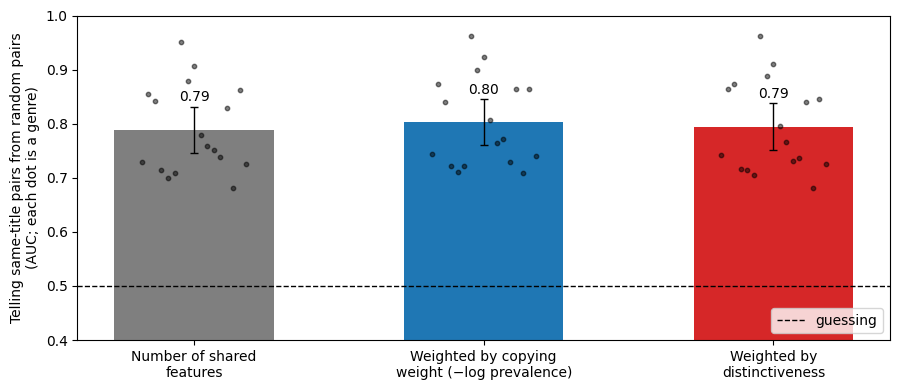

In [8]:
order = ['shared features, length-adjusted', 'copying weight, length-adjusted', 'distinctiveness, length-adjusted']
labels = ['Number of shared\nfeatures', 'Weighted by copying\nweight (−log prevalence)', 'Weighted by\ndistinctiveness']
def mean_ci(v):
    v = np.asarray(v, float); h = 2.262 * v.std(ddof=1) / np.sqrt(len(v)) if len(v) == 10 else __import__('scipy').stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v))
    return v.mean(), h
fig, ax = plt.subplots(figsize=(9.1, 4))
for k, (rule, col) in enumerate(zip(order, [GRAY, BLUE, RED])):
    mval, h = mean_ci(auc[rule])
    ax.bar(k, mval, 0.55, color=col, yerr=h, error_kw=ERR)
    ax.scatter(np.full(len(auc), k) + np.linspace(-0.18, 0.18, len(auc)), auc[rule], s=10, color='black', alpha=0.5, zorder=3)
    ax.annotate(f'{mval:.2f}', (k, mval + h), textcoords='offset points', xytext=(0, 4), ha='center')
ax.axhline(0.5, color='black', ls='--', lw=1, label='guessing')
ax.set_xticks(range(3)); ax.set_xticklabels(labels); ax.set_ylim(0.4, 1.0)
ax.set_ylabel('Telling same-title pairs from random pairs\n(AUC; each dot is a genre)'); ax.legend(loc='lower right')
save(fig, 'same_title_auc')

## Part D. Packages: one shared feature that nearly implies another

Two shared features are not always two pieces of evidence. If nearly every Western with a posse also has a sheriff, a second work that shares both adds little by sharing the second. The right weight for a pair is the surprisal of the pair, −log P(F₁ and F₂ | g) = −log P(F₁ | g) − log P(F₂ | F₁, g), and the second term is small when the first feature implies the second. This is the corpus form of "necessity": how likely one feature is given another, within the genre. Notebook 03c stores, for pairs of story features found together in at least five of a genre's films, the number of the genre's films with both.

For each of the six genres the cell lists candidate pairs of nouns and noun phrases, each in at least 20 of the genre's films: *implied* pairs, where the second is at least three times as likely given the first as in the genre at large and present in at least 30% of the films with the first; and *unrelated* pairs, where the conditional and the plain rate differ by less than a quarter.

In [9]:
import pyarrow.dataset as pads
local = TMP / 'combination_stockiness.parquet'
shutil.copy(V4 / '03c_network' / 'combination_stockiness.parquet', local)
cols = ['genre', 'element_i', 'element_type_i', 'taxonomy_i', 'element_j', 'element_type_j', 'taxonomy_j', 'joint_count_g']
ds = pads.dataset(local)
co = ds.to_table(columns=cols, filter=pads.field('genre').isin(SIX)).to_pandas()
ok_types = ['noun', 'chunk']; concrete = ['character_type', 'setting', 'object', 'event']
co = co[co.element_type_i.isin(ok_types) & co.element_type_j.isin(ok_types) & co.taxonomy_i.isin(concrete) & co.taxonomy_j.isin(concrete)]
cnt = d[d.is_narrative_element][['genre', 'element', 'element_type', 'film_count', 'N_g']]
co = co.merge(cnt.rename(columns={'element': 'element_i', 'element_type': 'element_type_i', 'film_count': 'n_i'}), on=['genre', 'element_i', 'element_type_i'])
co = co.merge(cnt.rename(columns={'element': 'element_j', 'element_type': 'element_type_j', 'film_count': 'n_j'})[['genre', 'element_j', 'element_type_j', 'n_j']], on=['genre', 'element_j', 'element_type_j'])
co = co[(co.n_i >= 20) & (co.n_j >= 20)]
both = pd.concat([co.assign(first=co.element_i, second=co.element_j, n_first=co.n_i, n_second=co.n_j),
                  co.assign(first=co.element_j, second=co.element_i, n_first=co.n_j, n_second=co.n_i)], ignore_index=True)
both['p_second'] = both['n_second'] / both['N_g']
both['p_second_given_first'] = both['joint_count_g'] / both['n_first']
both['ratio'] = both['p_second_given_first'] / both['p_second']
both = both[~both.apply(lambda r: bool(set(r['first'].split()) & set(r['second'].split())), axis=1)]      # no shared word (sheriff / new sheriff)
implied = both[(both.ratio >= 3) & (both.p_second_given_first >= 0.30) & (both.joint_count_g >= 10)]
unrelated = both[(both.ratio.between(0.8, 1.25)) & (both.joint_count_g >= 5)]
summary = pd.DataFrame({'implied pairs': implied.groupby('genre').size(), 'unrelated pairs': unrelated.groupby('genre').size()}).reindex(SIX).fillna(0).astype(int)
summary.to_csv(OUT / 'partD_pair_counts.csv')
out(''); out('D. CANDIDATE PAIRS OF CONCRETE STORY FEATURES (each in 20 or more of the genre\'s films)')
out(summary.to_string())
show = ['first', 'second', 'n_first', 'n_second', 'joint_count_g', 'p_second', 'p_second_given_first', 'ratio']
ex = pd.concat([implied[implied.genre == g].sort_values('p_second_given_first', ascending=False).head(8).assign(genre=g, kind='implied') for g in SIX] +
               [unrelated[unrelated.genre == g].sort_values('joint_count_g', ascending=False).head(4).assign(genre=g, kind='unrelated') for g in SIX])
ex[['genre', 'kind'] + show].to_csv(OUT / 'partD_pair_examples.csv', index=False)
for g in ['Western', 'Horror', 'Crime', 'Science Fiction']:
    out(''); out(f'D. {g.upper()}: implied pairs (the second given the first)')
    out(implied[implied.genre == g].sort_values('p_second_given_first', ascending=False).head(8)[show].round(3).to_string(index=False))
implied[['genre'] + show].to_csv(OUT / 'partD_implied_pairs.csv', index=False)
unrelated[['genre'] + show].to_csv(OUT / 'partD_unrelated_pairs.csv', index=False)


D. CANDIDATE PAIRS OF CONCRETE STORY FEATURES (each in 20 or more of the genre's films)
                 implied pairs  unrelated pairs
genre                                          
Western                    220             4464
Horror                    1081            31868
Science Fiction            601            22664
Crime                      739            30956
Fantasy                    529            17748
Comedy                    1476            62536

D. WESTERN: implied pairs (the second given the first)
       first second  n_first  n_second  joint_count_g  p_second  p_second_given_first  ratio
 confederate    war       26       189             20     0.139                 0.769  5.543
       range  horse       21       299             14     0.220                 0.667  3.037
     foreman  ranch       41       241             27     0.177                 0.659  3.722
  engagement father       20       288             13     0.211                 0.650  3.074
      

### Matched sets

The power simulations show that Study 2 is limited by how much pairs differ from one another, so the design matches each implied pair to an unrelated pair that shares its second feature and whose first feature is about as common (within a factor of 1.5 in the genre's films). The count below is the number of implied pairs for which at least one such partner exists, and the number of distinct second features they cover.

In [10]:
rows = []; examples = []
for g in SIX:
    im_ = implied[implied.genre == g]; un_ = unrelated[unrelated.genre == g]
    m = im_.merge(un_[['second', 'first', 'n_first', 'p_second_given_first']], on='second', suffixes=('', '_u'))
    m = m[(m['n_first_u'] / m['n_first']).between(1 / 1.5, 1.5) & (m['first'] != m['first_u'])]
    ok = m.drop_duplicates(['first', 'second'])
    rows.append({'genre': g, 'implied pairs': len(im_), 'with a matched unrelated partner': len(ok), 'distinct second features': ok['second'].nunique()})
    examples.append(m.sort_values('p_second_given_first', ascending=False).drop_duplicates('second').head(4).assign(genre=g))
matched = pd.DataFrame(rows).set_index('genre')
matched.to_csv(OUT / 'partD_matched_sets.csv')
out(''); out('D. MATCHED SETS FOR STUDY 2 (an implied pair and an unrelated pair that share the second feature)')
out(matched.to_string())
exm = pd.concat(examples)[['genre', 'second', 'first', 'p_second_given_first', 'first_u', 'p_second_given_first_u', 'p_second']]
exm.columns = ['genre', 'shared second feature', 'first (implied)', 'P(second | first)', 'first (unrelated)', 'P(second | first), unrelated', 'P(second)']
exm.to_csv(OUT / 'partD_matched_examples.csv', index=False)
out(exm.round(2).to_string(index=False))


D. MATCHED SETS FOR STUDY 2 (an implied pair and an unrelated pair that share the second feature)
                 implied pairs  with a matched unrelated partner  distinct second features
genre                                                                                     
Western                    220                               165                        41
Horror                    1081                               743                        73
Science Fiction            601                               489                        62
Crime                      739                               515                        66
Fantasy                    529                               335                        59
Comedy                    1476                               866                        70
          genre shared second feature         first (implied)  P(second | first) first (unrelated)  P(second | first), unrelated  P(second)
        Western                  

## Part E. Concrete story features available for synopses

The synopsis experiments need, for each genre and each of the four cells, story features that can be written into a plot: kinds of characters, settings, objects and events, as nouns or noun phrases. The count is over the law review study's eligible pool (story features in at least 20 of the genre's films, reviewed exclusions removed), with the cells defined as in the law review study (top and bottom thirds of the genre on each measure).

In [11]:
pool = pd.read_csv(V4 / '10_human_study_stimuli' / 'eligible_pool_predictors.csv')
pool = pool[(~pool['manual_exclude'].astype(bool)) & pool['element_type'].isin(['noun', 'chunk'])]
pool['cell'] = pool['prev_tercile'].str[0].str.upper() + pool['dist_tercile'].str[0].str.upper()
pc = pool[pool['cell'].isin(['HH', 'HL', 'LH', 'LL']) & pool['element_taxonomy'].isin(['character_type', 'setting', 'object', 'event'])]
feas = pc.groupby(['genre', 'cell', 'element_taxonomy']).size().unstack(fill_value=0).reindex(columns=['character_type', 'setting', 'object', 'event'])
feas.to_csv(OUT / 'partE_concrete_features_by_cell.csv')
out(''); out('E. CONCRETE STORY FEATURES IN THE LAW REVIEW STUDY POOL, BY GENRE AND CELL (nouns and noun phrases)')
out(feas.to_string())
wst = pc[pc.genre == 'Western'].sort_values(['cell', 'element_taxonomy', 'film_count'], ascending=[True, True, False])
wl = wst.groupby(['cell', 'element_taxonomy'])['element'].apply(lambda x: ', '.join(list(x)[:10])).unstack().reindex(columns=['character_type', 'setting', 'object', 'event'])
out(''); out('E. WESTERN: up to ten features per cell and kind, most frequent first')
for cell_, r in wl.iterrows():
    for k_, v in r.items():
        out(f'  {cell_} {k_:<15} {v}')


E. CONCRETE STORY FEATURES IN THE LAW REVIEW STUDY POOL, BY GENRE AND CELL (nouns and noun phrases)
element_taxonomy      character_type  setting  object  event
genre           cell                                        
Comedy          HH                72       29      78     61
                HL                91       61      53     82
                LH               133       46     131     88
                LL               103       51      61     58
Crime           HH                67       27      48     38
                HL                36       16      15     27
                LH                48       21      34     44
                LL                59       30      38     34
Fantasy         HH                32       28      21     15
                HL                25       20      15     20
                LH                26       18      47      9
                LL                40       21      20     26
Horror          HH                34       38

## Outputs

In [12]:
(OUT / 'corpus_inputs_report.txt').write_text('\n'.join(report) + '\n')
print(sorted(p.name for p in OUT.rglob('*') if p.is_file()))

['corpus_inputs_report.txt', 'design_inputs_from_law_review_study.html', 'law_review_study_h2_fixed_effects.csv', 'law_review_study_h2_variance_components.csv', 'law_review_study_item_means.csv', 'law_review_study_items_expected_by_prevalence.png', 'law_review_study_listing_rates.csv', 'partA_rank_checks.csv', 'partA_worked_example.csv', 'partB_cells.csv', 'partB_item_correlations.csv', 'partB_law_review_study_items_with_quantities.csv', 'partC_chance_overlap.csv', 'partC_same_title_auc.csv', 'partD_implied_pairs.csv', 'partD_matched_examples.csv', 'partD_matched_sets.csv', 'partD_pair_counts.csv', 'partD_pair_examples.csv', 'partD_unrelated_pairs.csv', 'partE_concrete_features_by_cell.csv', 'power_expert_counts.csv', 'power_one_feature_choice.csv', 'power_one_feature_ratings.csv', 'power_one_feature_ratings.png', 'power_one_feature_tracking.csv', 'power_one_feature_tracking.png', 'power_pairs.csv', 'power_pairs_matched.csv', 'power_two_works.csv', 'same_title_auc.png', 'tracking_studi